In [35]:
!pip install -q kagglehub

In [36]:
import kagglehub

path = kagglehub.dataset_download(
    "kaustubhdikshit/neu-surface-defect-database"
)

print("Dataset downloaded to:")
print(path)

Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Dataset downloaded to:
/kaggle/input/neu-surface-defect-database


In [37]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import classification_report, confusion_matrix

In [38]:
data_dir = os.path.join(path, "NEU-DET")

train_path = os.path.join(
    data_dir,
    "train",
    "images"
)

val_path = os.path.join(
    data_dir,
    "validation",
    "images"
)

print("\nClasses:")
print(os.listdir(train_path))


Classes:
['inclusion', 'scratches', 'pitted_surface', 'patches', 'crazing', 'rolled-in_scale']


In [39]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [40]:
train_dataset = datasets.ImageFolder(
    train_path,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_path,
    transform=val_transform
)

print("Classes:", train_dataset.classes)
print("Number of classes:", len(train_dataset.classes))

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Number of classes: 6
Training images: 1440
Validation images: 360


In [41]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 45
Validation batches: 12


In [42]:
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

print("ResNet50 loaded successfully!")

ResNet50 loaded successfully!


In [43]:
for param in model.parameters():
    param.requires_grad = False

print("ResNet layers frozen.")

ResNet layers frozen.


In [44]:
num_classes = len(train_dataset.classes)

model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

print("Number of output classes:", num_classes)

Number of output classes: 6


In [45]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print("Model is ready!")

Model is ready!


In [46]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

In [47]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    loss = running_loss / len(loader)
    accuracy = correct / total

    return loss, accuracy

In [48]:
def validate(model, loader, criterion):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    loss = running_loss / len(loader)
    accuracy = correct / total

    return loss, accuracy

In [49]:
epochs = 5

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = validate(
        model,
        val_loader,
        criterion
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch [1/5] Train Loss: 0.9983 Train Acc: 0.8000 Val Loss: 1.0264 Val Acc: 0.7361
Epoch [2/5] Train Loss: 0.3839 Train Acc: 0.9549 Val Loss: 0.4005 Val Acc: 0.9361
Epoch [3/5] Train Loss: 0.2586 Train Acc: 0.9653 Val Loss: 0.2814 Val Acc: 0.9472
Epoch [4/5] Train Loss: 0.1916 Train Acc: 0.9792 Val Loss: 0.2487 Val Acc: 0.9528
Epoch [5/5] Train Loss: 0.1562 Train Acc: 0.9785 Val Loss: 0.1884 Val Acc: 0.9611


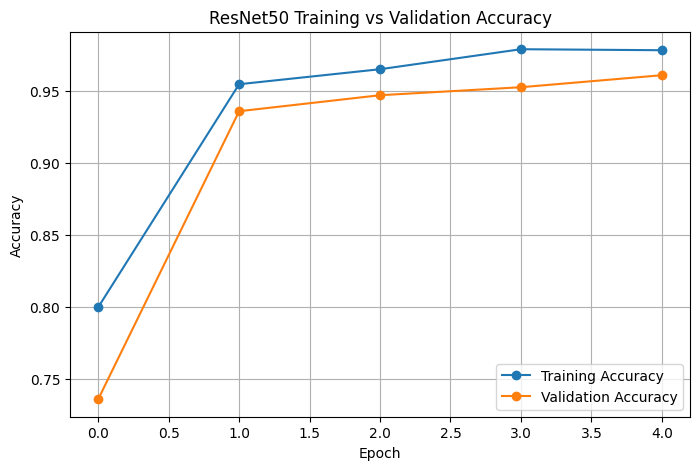

In [50]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Training vs Validation Accuracy")
plt.legend()
plt.grid()

plt.show()

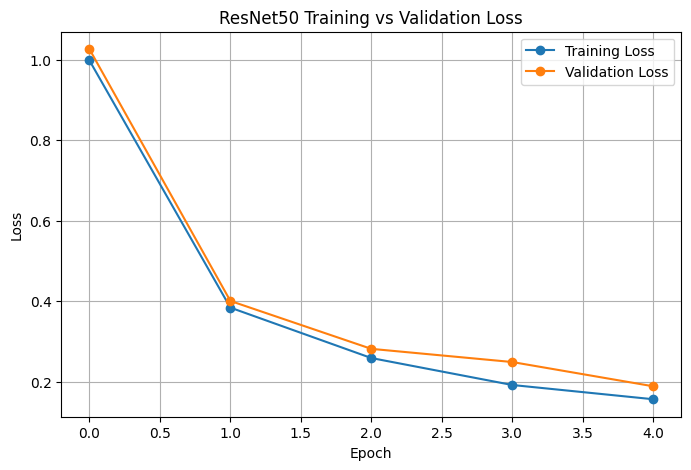

In [51]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Training vs Validation Loss")
plt.legend()
plt.grid()

plt.show()

In [52]:
for param in model.layer4.parameters():
    param.requires_grad = True

print("Layer4 has been unfrozen.")

Layer4 has been unfrozen.


In [53]:
optimizer = optim.Adam(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=0.0001
)

print("Fine-tuning optimizer created.")

Fine-tuning optimizer created.


In [54]:
fine_tune_epochs = 5

for epoch in range(fine_tune_epochs):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = validate(
        model,
        val_loader,
        criterion
    )

    print(
        f"Fine-tune Epoch [{epoch+1}/{fine_tune_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

Fine-tune Epoch [1/5] Train Loss: 0.0606 Train Acc: 0.9861 Val Loss: 0.0279 Val Acc: 0.9917
Fine-tune Epoch [2/5] Train Loss: 0.0157 Train Acc: 0.9972 Val Loss: 0.0135 Val Acc: 0.9944
Fine-tune Epoch [3/5] Train Loss: 0.0154 Train Acc: 0.9958 Val Loss: 0.0050 Val Acc: 0.9972
Fine-tune Epoch [4/5] Train Loss: 0.0110 Train Acc: 0.9979 Val Loss: 0.0066 Val Acc: 0.9972
Fine-tune Epoch [5/5] Train Loss: 0.0068 Train Acc: 0.9993 Val Loss: 0.0071 Val Acc: 0.9972


# **Evaluation**

In [55]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        _, predictions = torch.max(outputs, 1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

print("Predictions collected!")

Predictions collected!


In [56]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=val_dataset.classes
    )
)

                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        60
      inclusion       1.00      0.98      0.99        60
        patches       1.00      1.00      1.00        60
 pitted_surface       1.00      1.00      1.00        60
rolled-in_scale       1.00      1.00      1.00        60
      scratches       0.98      1.00      0.99        60

       accuracy                           1.00       360
      macro avg       1.00      1.00      1.00       360
   weighted avg       1.00      1.00      1.00       360



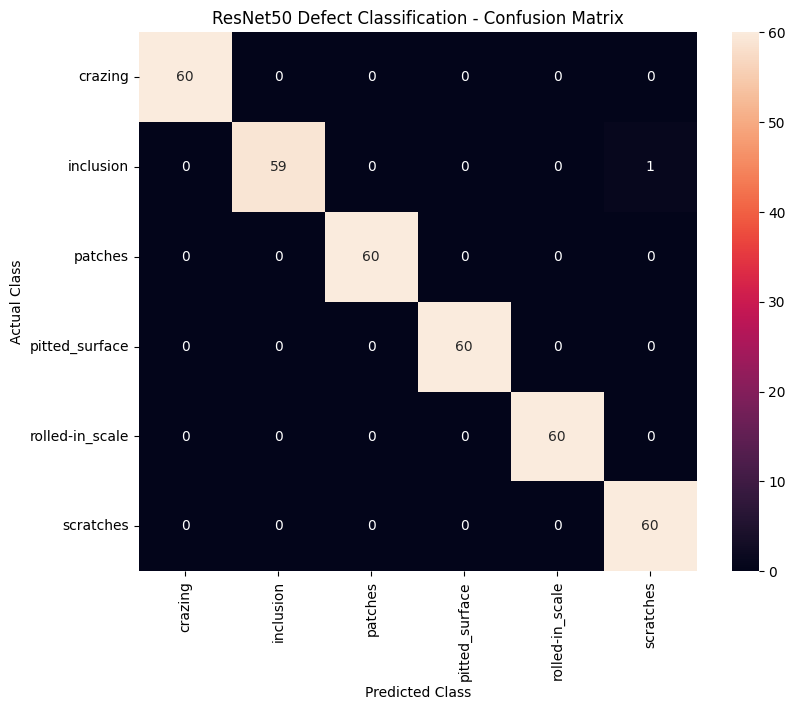

In [58]:
import seaborn as sns

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=val_dataset.classes,
    yticklabels=val_dataset.classes
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ResNet50 Defect Classification - Confusion Matrix")

plt.show()

In [59]:
def predict_image(model, image, class_names):

    model.eval()

    with torch.no_grad():
        image_tensor = image.unsqueeze(0).to(device)

        output = model(image_tensor)

        probabilities = torch.softmax(output, dim=1)

        confidence, predicted = torch.max(probabilities, 1)

    predicted_class = class_names[predicted.item()]
    confidence = confidence.item()

    return predicted_class, confidence

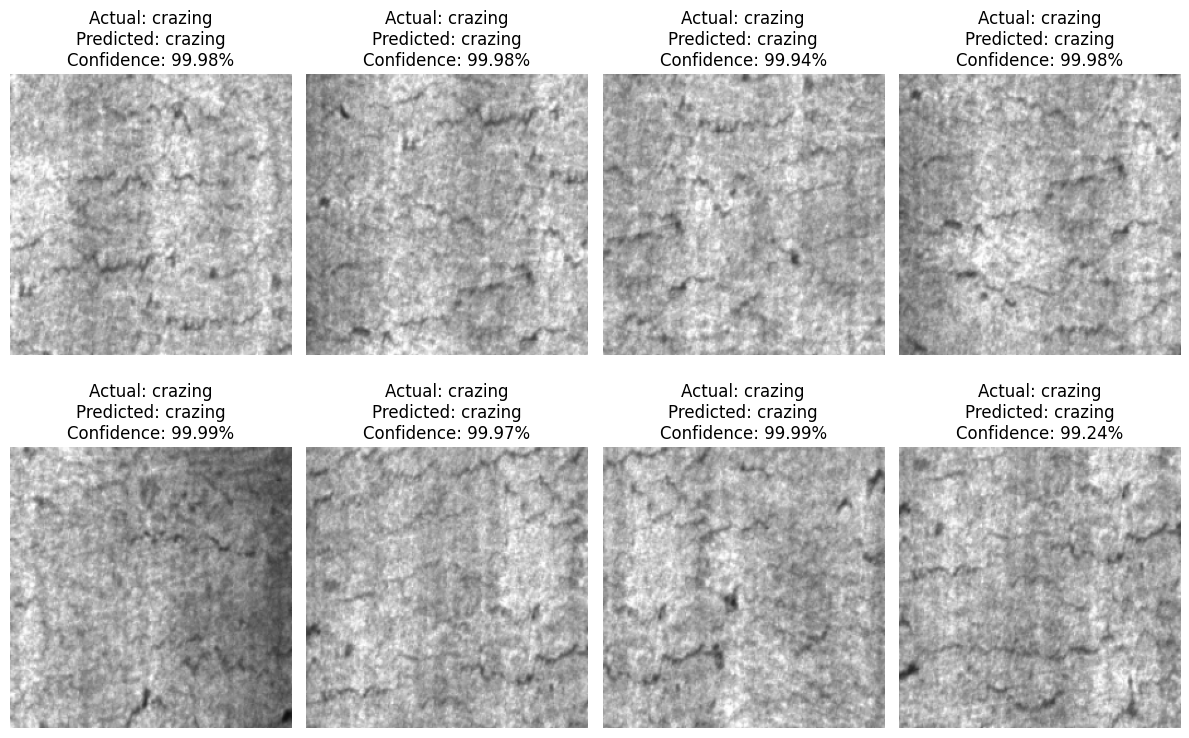

In [60]:
images, labels = next(iter(val_loader))

plt.figure(figsize=(12, 8))

for i in range(8):

    image = images[i]

    predicted_class, confidence = predict_image(
        model,
        image,
        val_dataset.classes
    )

    # Undo normalization
    mean = torch.tensor([0.485, 0.456, 0.406])
    std = torch.tensor([0.229, 0.224, 0.225])

    display_image = image.permute(1, 2, 0)
    display_image = display_image * std + mean
    display_image = torch.clamp(display_image, 0, 1)

    actual_class = val_dataset.classes[labels[i]]

    plt.subplot(2, 4, i + 1)

    plt.imshow(display_image)

    plt.title(
        f"Actual: {actual_class}\n"
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence:.2%}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [61]:
wrong_indices = []

for i in range(len(val_dataset)):

    image, label = val_dataset[i]

    predicted_class, confidence = predict_image(
        model,
        image,
        val_dataset.classes
    )

    predicted_label = val_dataset.class_to_idx[predicted_class]

    if predicted_label != label:
        wrong_indices.append(i)

print("Number of incorrect predictions:", len(wrong_indices))
print("Incorrect image indices:", wrong_indices)

Number of incorrect predictions: 1
Incorrect image indices: [102]


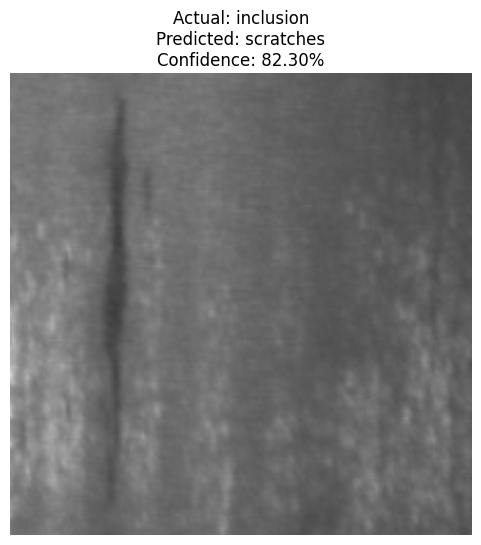

In [62]:
if len(wrong_indices) > 0:

    index = wrong_indices[0]

    image, label = val_dataset[index]

    predicted_class, confidence = predict_image(
        model,
        image,
        val_dataset.classes
    )

    actual_class = val_dataset.classes[label]

    # Undo normalization
    mean = torch.tensor([0.485, 0.456, 0.406])
    std = torch.tensor([0.229, 0.224, 0.225])

    display_image = image.permute(1, 2, 0)
    display_image = display_image * std + mean
    display_image = torch.clamp(display_image, 0, 1)

    plt.figure(figsize=(6, 6))

    plt.imshow(display_image)

    plt.title(
        f"Actual: {actual_class}\n"
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence:.2%}"
    )

    plt.axis("off")
    plt.show()